In [1]:
import copy
import os
import math
import time

import numpy as np
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from typing import Literal, Tuple, Callable, NamedTuple
import pandas as pd

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [2]:
def check_cuda_memory():
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)
    peak = torch.cuda.max_memory_allocated() / (1024 ** 3)

    print(f"Allocated: {allocated:.2f} GB | Reserved: {reserved:.2f} GB | Peak: {peak:.2f} GB")


In [3]:
def attention(Q, K, V):
    """Scaled dot product attention (notebook 3); broadcasts over any
    leading batch axes."""
    d = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d)
    weights = F.softmax(scores, dim=-1)
    return weights @ V, weights


class MultiHeadAttention(nn.Module):
    """Multi-head attention with learned projections (notebook 4)."""
    def __init__(self, num_hiddens: int, num_heads: int):
        super().__init__()

        self.num_heads = num_heads
        self.W_q = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_k = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_v = nn.Linear(num_hiddens, num_hiddens, bias=True)
        self.W_o = nn.Linear(num_hiddens, num_hiddens, bias=True)

    def split_heads(self, X: Tensor):
        """(batch, seq, num_hiddens) -> (batch, heads, seq, num_hiddens/heads)"""
        b, seq, _ = X.shape
        return X.reshape(b, seq, self.num_heads, -1).transpose(1, 2)

    def merge_heads(self, X: Tensor):
        """(batch, heads, seq, d_head) -> (batch, seq, num_hiddens)"""
        b, h, seq, d_head = X.shape
        return X.transpose(1, 2).reshape(b, seq, h * d_head)

    def forward(self, queries: Tensor, keys: Tensor, values: Tensor):
        """
        Input: (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        # project, then split into heads: each is (batch, heads, seq, d_head)
        Q = self.split_heads(self.W_q(queries))   # (batch, heads, seq, d_head)
        K = self.split_heads(self.W_k(keys))
        V = self.split_heads(self.W_v(values))
        output, self.attention_weights = attention(Q, K, V)
        return self.W_o(self.merge_heads(output))


class PositionWiseFFN(nn.Module):
    """
    The same two-layer MLP applied at every position from class,
    but this time with GELU activation and dropout applied in the FFN.
    """
    def __init__(self, num_hiddens: int, ffn_num_hiddens: int, dropout: float):
        super().__init__()

        # nn.Linear acts on the last dimension, i.e., on each position separately.
        self.net = nn.Sequential(
            nn.Linear(num_hiddens, ffn_num_hiddens),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_num_hiddens, num_hiddens))


    def forward(self, X: Tensor):
        """
        Input: (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        return self.net(X)


class AddNorm(nn.Module):
    def __init__(self, num_hiddens, dropout):
        super().__init__()

        # NOTE: the use of BatchNorm here instead of LayerNorm.
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.BatchNorm1d(num_hiddens)

    def forward(self, X: Tensor, Y: Tensor):
        """
        Input: X (batch, seq, num_hiddens),
               Y (batch, seq, num_hiddens)
        Output: (batch, seq, num_hiddens)
        """
        # X: the sublayer's input; Y: the sublayer's output
        residual_update = self.dropout(Y) + X
        return self.norm(residual_update.transpose(1, 2)).transpose(1, 2)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, num_hiddens: int, ffn_num_hiddens: int, num_heads: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(num_hiddens, num_heads)
        self.addnorm1 = AddNorm(num_hiddens, dropout)
        self.ffn = PositionWiseFFN(num_hiddens, ffn_num_hiddens, dropout)
        self.addnorm2 = AddNorm(num_hiddens, dropout)

    def forward(self, X: Tensor):
        """
        Input/Output: (batch * num_channels, num_patches, num_hiddens)
        """
        Y = self.addnorm1(X, self.attention(X, X, X))
        return self.addnorm2(Y, self.ffn(Y))


class PatchPositionalEmbedding(nn.Module):
    """
    Produce 'embeddings' of patches through:
    - A linear project that maps patches in dimension `p` to dimension `d = num_hiddens`.
    - A trained lookup matrix that encodes position of `N` patches.

    Output of this layer is flattened in the (batch x channel) dimension so input into
    MultiHeadAttention is the standard (samples, sequence, embed_d) shape.
    """
    def __init__(self, num_patches: int, patch_size: int, num_hiddens: int):
        super().__init__()
        self.W_patch = nn.Linear(patch_size, num_hiddens, bias=True)

        W_position = torch.empty((num_patches, num_hiddens))
        nn.init.uniform_(W_position, -0.02, 0.02)
        self.W_position = nn.Parameter(W_position)

    def forward(self, X: Tensor):
        """
        Input: (batch * num_channels, num_patches, patch_size)
        Output: (batch * num_channels, num_patches, num_hiddens)
        """
        return self.W_patch(X) + self.W_position


class Patcher(nn.Module):
    def __init__(self, patch_size: int, stride: int):
        super().__init__()
        self.patch_size = patch_size
        self.stride = stride
        self.padding = nn.ReplicationPad1d((0, stride))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, num_patches, patch_size)
        """
        return self.padding(X).unfold(dimension=-1, size=self.patch_size, step=self.stride)


class RevIN(nn.Module):
    """
    Reversible Instance Normalization: Normalize each time series (channel) with zero
    mean and a std dev of 1. Reverse this procedure when `'denorm'`ing.

    The official PatchTST implementation released with the paper uses the implementation
    from https://github.com/ts-kim/RevIN/blob/master/RevIN.py, copied here.

    MIT License

    Copyright (c) 2022 Electronics and Telecommunications Research Institute (ETRI)

    Permission is hereby granted, free of charge, to any person obtaining a copy
    of this software and associated documentation files (the "Software"), to deal
    in the Software without restriction, including without limitation the rights
    to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
    copies of the Software, and to permit persons to whom the Software is
    furnished to do so, subject to the following conditions:

    The above copyright notice and this permission notice shall be included in all
    copies or substantial portions of the Software.

    THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
    IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
    FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
    AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
    LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
    OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
    SOFTWARE.
    """
    def __init__(self, num_features: int, eps=1e-5, affine=True):
        """
        :param num_features: the number of features or channels
        :param eps: a value added for numerical stability
        :param affine: if True, RevIN has learnable affine parameters
        """
        super(RevIN, self).__init__()
        self.num_features = num_features
        self.eps = eps
        self.affine = affine
        if self.affine:
            self._init_params()

    def forward(self, x, mode: Literal["norm"]|Literal["denorm"]):
        """
        Input/Output: (batch, num_channels, lookback_size)
        Original code works on the last two dimensions transposed.
        """
        x = x.transpose(1, 2)
        if mode == 'norm':
            self._get_statistics(x)
            x = self._normalize(x)
        elif mode == 'denorm':
            x = self._denormalize(x)
        else: raise NotImplementedError

        x = x.transpose(1, 2)
        return x

    def _init_params(self):
        # initialize RevIN params: (C,)
        self.affine_weight = nn.Parameter(torch.ones(self.num_features))
        self.affine_bias = nn.Parameter(torch.zeros(self.num_features))

    def _get_statistics(self, x):
        dim2reduce = tuple(range(1, x.ndim-1))
        self.mean = torch.mean(x, dim=dim2reduce, keepdim=True).detach()
        self.stdev = torch.sqrt(torch.var(x, dim=dim2reduce, keepdim=True, unbiased=False) + self.eps).detach()

    def _normalize(self, x):
        x = x - self.mean
        x = x / self.stdev
        if self.affine:
            x = x * self.affine_weight
            x = x + self.affine_bias
        return x

    def _denormalize(self, x):
        if self.affine:
            x = x - self.affine_bias
            x = x / (self.affine_weight + self.eps*self.eps)
        x = x * self.stdev
        x = x + self.mean
        return x


class PatchTSTParams(NamedTuple):
    num_channels: int  # Number of individual time series in multivariate series.
    patch_size: int=16
    stride: int=8
    lookback_size: int=512
    prediction_size: int=96
    num_hiddens: int=128
    ffn_num_hiddens: int=256
    num_heads: int=16
    num_blocks: int=3
    dropout: float=0.2

    def __str__(self):
        return f"PatchTST(M={self.num_channels}, L={self.lookback_size}, T={self.prediction_size})"


class PatchTST(nn.Module):
    """
    PatchTST architecture. Default parameter values are from the original paper.

    The default lookback window size of 512 time steps produces 64 patches with the
    default patch size of 16 and stride of 8. Another common variant is a
    lookback size of 336, producing 42 patches.

    The original paper tests models over prediction time horizons of 96, 192, 336,
    and 720. In the official source code, dropout is applied after positional encoding
    and in the transformer encoder block.
    """
    def __init__(self, args: PatchTSTParams):
        super().__init__()
        self.args = args
        self.num_patches = int((args.lookback_size - args.patch_size) / args.stride) + 2

        # Normalization layer standardizes each channel individually.
        self.norm = RevIN(num_features=args.num_channels, affine=False)
        self.patch = Patcher(args.patch_size, args.stride)
        self.embedding = PatchPositionalEmbedding(self.num_patches, args.patch_size, args.num_hiddens)
        self.dropout = nn.Dropout(args.dropout)

        self.blks = nn.ModuleList([
            TransformerEncoderBlock(args.num_hiddens, args.ffn_num_hiddens, args.num_heads, args.dropout)
            for _ in range(args.num_blocks)
        ])

        self.decoder = nn.Sequential(
            nn.Flatten(start_dim=-2),
            nn.Linear(self.num_patches * args.num_hiddens, args.prediction_size))

    def forward(self, X: Tensor):
        """
        Input: (batch, num_channels, lookback_size)
        Output: (batch, num_channels, prediction_size)

        Each channel is one time series from the multivariate series.
        """
        batch, num_channels, _ = X.shape

        # (batch, num_channels, num_patches, patch_size)
        patched_X = self.patch(self.norm(X, mode="norm"))
        assert self.num_patches == patched_X.shape[2], \
            f"Expected num patches = {self.num_patches}. Actual = {patched_X.shape[2]}"

        # (batch * num_channels, num_patches, num_hiddens)
        # Batch and channels flattened together.
        X_batch_channel_flattened = patched_X.flatten(start_dim=0, end_dim=1)
        patch_embeds: Tensor = self.dropout(self.embedding(X_batch_channel_flattened))

        for blk in self.blks:
            patch_embeds = blk(patch_embeds)

        # (batch, num_channels, num_patches, num_hiddens)
        # NOTE: The official code transposes the last two dimensions before feeding into
        # the decoder head. It shouldn't matter, but perhaps worth investigating if this
        # doesn't perform...
        patch_embeds = patch_embeds.unflatten(dim=0, sizes=(batch, num_channels))
        predictions = self.decoder(patch_embeds)
        return self.norm(predictions, mode="denorm")

In [4]:
class RandomizedChannelDataset(TensorDataset):
    """
    TensorDataset that randomly samples `channel_window_size` channels per item.

    Loading wide datasets (e.g., the traffic dataset which has 862 individual series)
    does not work with our GPU's available memory.

    The goal of this dataset is to randomly select a subset of channels for each sample
    in TRAINING. This allows our model to gradually see all channels in the dataset
    while still working within the limits of our GPU's memory by individually processing
    a subset of channels in a batch, and random sub-sampling is considerably faster
    for training.

    This dataset should ideally be used in conjunction with `TensorDataset`:
    - `RandomizedChannelDataset` speeds up training by only using `channel_window_size`
      channels per sample.
    - `TensorDataset` should be used with the validation and test sets so
      evaluation is done over all channels for all samples. Channel windowing is
      handled in the `evaluate` method to avoid overloading the GPU.
      Using a `RandomizedChannelDataset` loader for all splits can speed up
      both training and evaluation, which may be ideal for your use-case.

    Input tensors should have the shape:
        `(N_samples, num_all_channels, lookback/prediction_size)`,
    then this dataset will yield items of shape:
        `(channel_window_size, lookback/prediction_size)`.

    The entire return value is a tuple:
        `(batch_item_x, batch_item_y, random_channels)`
    A `DataLoader` stacks these return values to produce a batch triple with shape:
        batch_X:         `(batch_size, channel_window_size, lookback_size)`,
        batch_Y:         `(batch_size, channel_window_size, prediction_size)`,
        random_channels: `(batch_size, random_channels)`,


    IMPORTANT: This dataset may ONLY be used if `affine=False` in the RevIN layer, or
    PatchTST's `num_channels` is set to match `channel_window_size`.
    """
    DEFAULT_CHANNEL_WINDOW_SIZE = 10

    def __init__(
            self,
            *tensors: Tensor,
            channel_window_size: int = DEFAULT_CHANNEL_WINDOW_SIZE
    ) -> None:
        super().__init__(*tensors)
        self.num_all_channels = self.tensors[0].shape[1]
        self.channel_window_size = min(channel_window_size, self.num_all_channels)

    def __getitem__(self, index):
        # X[index] shape (num_channels, lookback_size)
        # Y[index] shape (num_channels, prediction_size)
        # where num_channels is all the channels.
        #
        # Randomly select self.channel_window_size channels to return
        # tensors of size (N, channel_window_size, window_size)
        random_channels = torch.randperm(self.num_all_channels)[:self.channel_window_size]
        return *tuple(tensor[index, random_channels] for tensor in self.tensors), random_channels


def load_time_series_data(
    file_path: str,
    delimiter: str = ",",
) -> np.ndarray:
    """
    Load raw multivariate time-series data into a 2D float tensor of shape (T, num_channels).

    The file is expected to be a text file with no header row or index (time) column. I.e., it
    should directly be raw data rows. Each row must record a timestamp, and each column a channel
    of the multivariate series.
    """
    arr = np.loadtxt(file_path, delimiter=delimiter)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D tensor of shape (T, num_channels), got shape {arr.shape}")

    return arr


def to_data_loader(data: Dataset, batch_size: int, collate_fn=None, shuffle=False, seed=SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)

    return DataLoader(
        data,
        batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        generator=g)


def split_time_series_data(
    raw_data: np.ndarray,
    lookback_size: int,
    prediction_size: int,
    split_ratios: Tuple[float, float, float] = (0.7, 0.1, 0.2),
    batch_size: int = 24,
    use_randomized_loaders: bool = True,
    dtype: torch.dtype = torch.float32,
) -> Tuple[
    DataLoader[RandomizedChannelDataset],
    DataLoader[TensorDataset|RandomizedChannelDataset],
    DataLoader[TensorDataset|RandomizedChannelDataset],
    StandardScaler
]:
    """
    Construct a PyTorch TensorDataset containing (X, Y) sliding-window pairs. Each window pair
    logically consists of X_i = [...lookback_size...] historic time steps used to predict
    Y_i = [...prediction_size...] events into the future, for each channel.

    In other words,
        X[i] = data[i : i + lookback_size]^T    shape: (num_channels, lookback_size)
        Y[i] = data[i + lookback_size : i + lookback_size + prediction_size]^T
                                                shape: (num_channels, prediction_size)
    Returns:
       train/val/test: `DataLoader`s, containing `TensorDataset`s that have:
                tensors[0] (X): shape (N, num_channels, lookback_size)
                tensors[1] (Y): shape (N, num_channels, prediction_size)
            where N is the number of valid sliding windows. Data is standardized.
            `use_randomized_loaders` controls whether or not val/test splits use
            `RandomizedChannelDataset` or `TensorDataset`. I.e., whether or not
            val/test splits get a dataset that yields _all_ data or a random
            sub-sample of channels.

        scaler: the `StandardScaler` used to standardize the data, in order to
            reverse the process for plotting in the original scale of the data.
    """
    scaler = StandardScaler()
    has_fit = False
    def lookback_and_prediction_windows(split: np.ndarray) -> Dataset:
        nonlocal scaler, has_fit
        split = scaler.transform(split) if has_fit else scaler.fit_transform(split)

        # Stride of 1: heavily overlap samples.
        # Unfolding yields the shape (N_samples, channels, window_size)
        tensor = torch.from_numpy(split).to(dtype=dtype)
        X = tensor.unfold(dimension=0, size=lookback_size, step=1)
        Y = tensor[lookback_size:].unfold(dimension=0, size=prediction_size, step=1)

        num_samples = min(X.shape[0], Y.shape[0])
        if has_fit:
            DatasetConstr = RandomizedChannelDataset if use_randomized_loaders else TensorDataset
            dataset = DatasetConstr(X[:num_samples], Y[:num_samples])
        else:
            dataset = RandomizedChannelDataset(X[:num_samples], Y[:num_samples])

        has_fit = True

        return dataset

    num_timesteps, _ = raw_data.shape

    train_ratio, val_ratio, _ = split_ratios
    train_size = int(num_timesteps * train_ratio)
    val_size = int(num_timesteps * val_ratio)
    test_size = num_timesteps - train_size - val_size

    # Pull lookback windows in val/test from the split before it (predicted values
    # in val/test are never seen from another split).
    # This matches the offical code's implementation.
    train_dataset, val_dataset, test_dataset = map(lookback_and_prediction_windows, [
        raw_data[:train_size],
        raw_data[train_size - lookback_size:train_size + val_size],
        raw_data[num_timesteps - test_size - lookback_size:],
    ])

    return to_data_loader(train_dataset, batch_size, shuffle=True), \
            to_data_loader(val_dataset, batch_size), \
            to_data_loader(test_dataset, batch_size), \
            scaler

In [5]:
def train_epoch(
        model: nn.Module,
        train_loader: DataLoader,
        loss_fn,
        optimizer) -> float:
    model.train()
    total_loss = 0.0   # sum of per-example losses
    total_examples = 0
    for batch in train_loader:
        X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

        # Typical training workflow: Dataset/loader are on the CPU.
        # Just load one batch to the GPU.
        X, y = X.to(device), y.to(device)
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # loss_fn returns the mean over the batch, so multiply back out by the
        # batch size to accumulate an exact, example-weighted average (the final
        # batch is smaller, so a plain mean of batch means would be biased).
        total_loss += loss.item() * y.numel()
        total_examples += y.numel()

    return total_loss / total_examples


def evaluate(
        model: nn.Module,
        data_loader: DataLoader[TensorDataset],
        loss_fn: nn.Module,
        channel_chunk_size=96) -> float:
    # channel_chunk_size: Take small windows of channels to avoid running out of memory
    # on the GPU. This works with a validation/test dataloader that does not do any
    # windowing of channels (a plain TensorDataset), or one that is already windowing
    # RandomizedChannelDataset (in which case splitting here may only yield one item).
    model.eval()
    total_loss = 0.0
    count = 0
    with torch.no_grad():
        for batch in data_loader:  # (batch_size, channels, time_window_size)
            X, y = batch[0], batch[1]  # Work with TensorDataset or RandomizedChannelDataset

            for Xc, yc in zip(X.split(channel_chunk_size, dim=1), y.split(channel_chunk_size, dim=1)):
                Xc, yc = Xc.to(device), yc.to(device)
                total_loss += loss_fn(model(Xc), yc).item() * yc.numel()
                count += yc.numel()
    return total_loss / count


def train_early_stopping(
        model: nn.Module,
        train_loader,
        valid_loader,
        loss_fn,
        optimizer,
        epochs,
        verbosity: Literal[0]|Literal[1]|Literal[2] = 0
) -> tuple[list[float], list[float]]:
    best_val_loss = float('inf')
    patience_counter = 0
    patience = 10          # number of epochs to wait for an improvement
    best_state = None

    train_losses, valid_losses = [], []
    for epoch in range(epochs):
        start = time.time()
        train_loss = train_epoch(model, train_loader, loss_fn, optimizer)
        if verbosity > 1:
            print(f'  train time {time.time() - start:.0f}s')

        eval_start = time.time()
        val_loss = evaluate(model, valid_loader, loss_fn)
        if verbosity > 1:
            print(f'  eval time {time.time() - eval_start:.0f}s')

        if verbosity > 0:
            print(f'epoch {epoch + 1:2d}  train loss {train_loss:.3f}  '
                f'val loss {val_loss:.3f}  '
                f'({time.time() - start:.0f}s)')
            if epoch % 5 == 0 and verbosity > 1:
                check_cuda_memory()

        train_losses.append(train_loss)
        valid_losses.append(val_loss)

        if val_loss < best_val_loss:
            # still improving: remember this model as the best so far
            best_val_loss = val_loss
            patience_counter = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            # not better than our current best.  keep training for a few more epochs
            # to give it a chance to improve (that is what `patience` controls)
            patience_counter += 1
            if patience_counter >= patience:
                break

    # Restore the best weights before evaluating. Large LRs will fail
    # to produce a validation loss < best_val_loss. Don't restore to
    # anything in this case.
    if best_state:
        model.load_state_dict(best_state)

    return train_losses, valid_losses


def plot_loss(
    train_losses: list[float],
    val_losses: list[float],
    title: str = ""
):
    epochs_axis = range(1, len(train_losses) + 1)
    _, ax_loss = plt.subplots(figsize=(4, 2.4))

    l1 = ax_loss.plot(epochs_axis, train_losses, label='training loss')
    l2 = ax_loss.plot(epochs_axis, val_losses, label='validation loss')
    ax_loss.set_xlabel('epoch')
    ax_loss.set_ylabel('loss')

    lines = l1 + l2
    ax_loss.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.3, 1), loc='upper left')
    plt.title(title)


class ExperimentRunner:
    """
    A class that facilitates experimenting with different model configurations.
    Each added experiment gets `n` models trained with a different random seed (`n = 5`).
    Averaged results are returned in a dataframe after evaluating the models against
    the validation set. Plotting some/all of the experiments is also possible.
    """
    REPORT_COLUMNS = ["Classifier", "Loss (val)", "Epochs", "Param count"]

    # Results used in plots, saved in case we want to recall results from this
    # runner without re-running all experiments.
    class ExpResults(NamedTuple):
        params: NamedTuple
        model: nn.Module
        train_losses: list[float]
        val_losses: list[float]

    def __init__(self, model_constr: Callable[[NamedTuple], nn.Module]):
        self.model_constr = model_constr

        # Subclass used for hyperparams. E.g., TDNNHyperParams. Model must be
        # constructable by running model_constr(experiment_params).
        self.experiments: list[NamedTuple] = []
        self.experiments_to_plot: set[str] = set()
        self.experiment_results: list[ExperimentRunner.ExpResults] = []

        self.epochs: int = -1
        self.lr: float = 0.0001
        self.train_loader = None
        self.val_loader = None

    def with_epochs(self, epochs: int) -> ExperimentRunner:
        self.epochs = epochs
        return self

    def with_lr(self, lr: float) -> ExperimentRunner:
        self.lr = lr
        return self

    def with_data(self, train_loader: DataLoader, val_loader: DataLoader) -> ExperimentRunner:
        self.train_loader = train_loader
        self.val_loader = val_loader
        return self

    def add_experiments(self, *params) -> ExperimentRunner:
        self.experiments.extend(params)
        return self

    def and_plot(self, *params) -> ExperimentRunner:
        """Plot a given set of hyper params. These must match planned experiments."""
        self.experiments_to_plot.update(map(str, params))
        return self

    def with_plots(self) -> ExperimentRunner:
        """Plot all experiments recorded thus far when this runner is executed."""
        self.experiments_to_plot.update(map(str, self.experiments))
        return self

    def get_results(self) -> list[ExperimentRunner.ExpResults]:
        return self.experiment_results.copy()

    def run(self, verbosity: Literal[0]|Literal[1]|Literal[2] = 0) -> pd.DataFrame:
        run_data = []
        for params in self.experiments:
            plot_name = None
            serialized_params = str(params)
            print(f"Running experiment: {params}")

            if serialized_params in self.experiments_to_plot:
                plot_name = serialized_params

            model = self.model_constr(params).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=self.lr)
            # scheduler = torch.optim.lr_scheduler.OneCycleLR(
            #     optimizer,
            #     pct_start=0.2,
            #     max_lr=self.lr,
            #     epochs=self.epochs,
            #     steps_per_epoch=len(self.train_loader))
            loss_fn = nn.MSELoss()

            train_losses, val_losses = train_early_stopping(
                model,
                self.train_loader,
                self.val_loader,
                loss_fn=loss_fn,
                optimizer=optimizer,
                epochs=self.epochs,
                verbosity=verbosity)
            self.experiment_results.append(ExperimentRunner.ExpResults(
                params=params,
                model=model.cpu(),
                train_losses=train_losses,
                val_losses=val_losses))
            if plot_name:
                plot_loss(
                    train_losses=train_losses,
                    val_losses=val_losses,
                    title=plot_name,
                )

            param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
            actual_epochs = len(train_losses)
            run_data.append([serialized_params, min(val_losses), actual_epochs, param_count])

        df = pd.DataFrame(
            run_data,
            columns=self.REPORT_COLUMNS
        )
        return df.round(4).astype(object).fillna("Diverged")


In [6]:
# NOTE: This only works with TensorDataset.
# `show_prediction_from_randomized_channel_set` works with RandomizedChannelDataset.
def show_random_prediction(model: nn.Module, loader: DataLoader[TensorDataset], scaler: StandardScaler):
    # Grab the first sample from the first batch, channel 0.
    # When using the val loader, this sample starts on line 11,769 of
    # the full dataset.
    # The scaler expects items in the shape (time, num_channels).
    sample_idx = 0
    random_time = np.random.randint(0, len(loader.dataset))
    X, Y = loader.dataset[random_time]
    channel = np.random.randint(0, len(X))
    sample = Tensor(scaler.inverse_transform(X.T).T[channel])
    truth = Tensor(scaler.inverse_transform(Y.T).T[channel])

    with torch.no_grad():
        single_sample_batch = X.unsqueeze(0)
        model = model.to(device)
        model.eval()
        all_preds = model(single_sample_batch.to(device)).cpu()
        preds = scaler.inverse_transform(all_preds[0].T).T[channel]

    print("lookback window, future truth, future prediction",
          sample.shape, truth.shape, preds.shape)

    _, ax = plt.subplots(figsize=(10, 4))

    prediction_xticks = np.arange(len(sample), len(sample) + len(truth))
    l1 = ax.plot(sample, label='lookback window')
    l2 = ax.plot(prediction_xticks, truth,
                label='true future series')
    l3 = ax.plot(prediction_xticks, preds,
                label='predicted future series')

    lines = l1 + l2 + l3
    ax.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.05, 1), loc='upper left');


# Plotting method that works with RandomizedChannelDataset loaders.
def show_prediction_from_randomized_channel_set(
        model: nn.Module,
        loader: DataLoader[RandomizedChannelDataset],
        scaler: StandardScaler):
    # Grab the first sample from the first batch, first channel in the batch.
    sample_idx = 0
    channel_in_batch = 0
    X, Y, random_channels = next(iter(loader))
    sample_lookback = X[sample_idx, channel_in_batch]
    future_truth = Y[sample_idx, channel_in_batch]
    channel_in_raw_data = random_channels[sample_idx, channel_in_batch]

    with torch.no_grad():
        single_sample_batch = X[sample_idx].unsqueeze(0)
        model = model.to(device)
        model.eval()
        all_preds = model(single_sample_batch.to(device)).cpu()
        future_prediction = all_preds[0, channel_in_batch]

    # Inverse transformation.
    # Because RandomizedChannelDataset serves batches with random channels, we need
    # to find the mean/std of the original channel in the scaler so we can reverse the
    # transform.
    channel_mean = scaler.mean_[channel_in_raw_data]
    channel_scale = scaler.scale_[channel_in_raw_data]
    sample_lookback *= channel_scale
    future_truth *= channel_scale
    future_prediction *= channel_scale
    sample_lookback += channel_mean
    future_truth += channel_mean
    future_prediction += channel_mean

    print("lookback window, future truth, future prediction",
          sample_lookback.shape, future_truth.shape, future_prediction.shape)

    _, ax = plt.subplots(figsize=(10, 4))

    prediction_xticks = np.arange(len(sample_lookback), len(sample_lookback) + len(future_truth))
    l1 = ax.plot(sample_lookback, label='lookback window')
    l2 = ax.plot(prediction_xticks, future_truth,
                label='true future series')
    l3 = ax.plot(prediction_xticks, future_prediction,
                label='predicted future series')

    lines = l1 + l2 + l3
    ax.legend(lines, [ln.get_label() for ln in lines], bbox_to_anchor=(1.05, 1), loc='upper left');



In [ ]:
# Take only 100 channels to avoid the GPU from running out of memory.
# TODO(ianfisk): Randomize this? Pick a smaller, more interesting dataset?
raw_data = load_time_series_data("./data/traffic.txt", delimiter=",")[:, 0:100]
raw_data.shape

(17544, 100)

In [ ]:
train_loader, val_loader, test_loader, scaler_large_data = split_time_series_data(
    raw_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=12,  # For less memory allocation.
    use_randomized_loaders=False)

example_batch_X, example_batch_Y = next(iter(train_loader))
print(f"batch_X shape: {example_batch_X.shape}")
print(f"batch_y shape: {example_batch_Y.shape}")

batch_X shape: torch.Size([12, 100, 512])
batch_y shape: torch.Size([12, 100, 96])


### NOTE:
The next two experiment runners tain the model with `affine=True` in the `RevIN` layer. This allocates a parameter per channel, which could have been contributing to memory issues seen with `batch_size=24` and all 800 some channels.

Running experiment: PatchTST(M=100, L=512, T=96)
epoch  1  train loss 0.281  val loss 0.228  (141s)
epoch  2  train loss 0.245  val loss 0.228  (142s)
epoch  3  train loss 0.237  val loss 0.227  (142s)
epoch  4  train loss 0.233  val loss 0.223  (142s)
epoch  5  train loss 0.229  val loss 0.220  (142s)
epoch  6  train loss 0.226  val loss 0.222  (142s)
epoch  7  train loss 0.223  val loss 0.218  (142s)
epoch  8  train loss 0.221  val loss 0.217  (167s)
epoch  9  train loss 0.219  val loss 0.216  (280s)
epoch 10  train loss 0.217  val loss 0.215  (280s)
epoch 11  train loss 0.215  val loss 0.216  (280s)
epoch 12  train loss 0.213  val loss 0.214  (280s)
epoch 13  train loss 0.212  val loss 0.214  (280s)
epoch 14  train loss 0.211  val loss 0.214  (278s)
epoch 15  train loss 0.210  val loss 0.212  (280s)
epoch 16  train loss 0.208  val loss 0.211  (278s)
epoch 17  train loss 0.207  val loss 0.213  (280s)
epoch 18  train loss 0.206  val loss 0.211  (280s)
epoch 19  train loss 0.205  val l

,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=100, L=512, T=96)",0.205,36,1194536


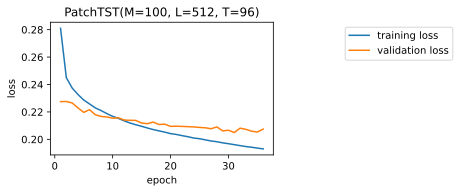

In [ ]:
runner = (
    ExperimentRunner(PatchTST)
        .with_epochs(400)
        .with_data(train_loader, val_loader)
        .add_experiments(
            PatchTSTParams(
                num_channels=100,
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results = runner.run(verbosity=1)
results

In [ ]:
num_channels = 5
small_data = load_time_series_data("./data/traffic.txt", delimiter=",")[:, 0:num_channels]
train_loader_sm, val_loader_sm, test_loader_sm, scaler_small_data = split_time_series_data(
    small_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=36,  # For less memory allocation.
    use_randomized_loaders=False)

Running experiment: PatchTST(M=5, L=512, T=96)
epoch  1  train loss 0.356  val loss 0.223  (6s)
epoch  2  train loss 0.290  val loss 0.219  (6s)
epoch  3  train loss 0.280  val loss 0.218  (6s)
epoch  4  train loss 0.274  val loss 0.219  (6s)
epoch  5  train loss 0.270  val loss 0.219  (6s)
epoch  6  train loss 0.266  val loss 0.217  (6s)
epoch  7  train loss 0.262  val loss 0.218  (6s)
epoch  8  train loss 0.260  val loss 0.218  (6s)
epoch  9  train loss 0.256  val loss 0.221  (6s)
epoch 10  train loss 0.254  val loss 0.218  (6s)
epoch 11  train loss 0.251  val loss 0.219  (6s)


,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=5, L=512, T=96)",0.2172,11,1194346


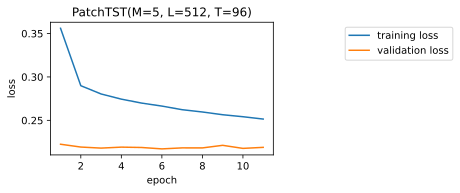

In [ ]:
runner2 = (
    ExperimentRunner(PatchTST)
        .with_epochs(400)
        .with_data(train_loader_sm, val_loader_sm)
        .add_experiments(
            PatchTSTParams(
                num_channels=num_channels,
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results = runner2.run(verbosity=1)
results

**Why is validation loss so low from the beginning??**

lookback window, future truth, future prediction (512,) (96,) (96,)


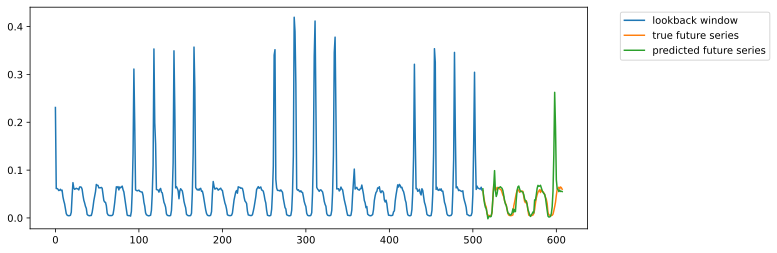

In [ ]:
# Model trained on 100 channels.
show_random_prediction(runner.get_results()[0].model, val_loader, scaler_large_data)

lookback window, future truth, future prediction (512,) (96,) (96,)


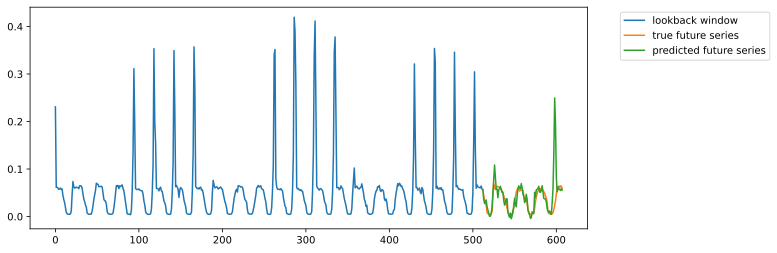

In [ ]:
# Model trained on 5 channels.
show_random_prediction(runner2.get_results()[0].model, val_loader_sm, scaler_small_data)

### Testing Training with Random Channel Sampling
The next experiment runners train the models with `affine=False` in the `RevIN` layer. This prevents allocating a parameter per channel, which could have been contributing to memory pressure seen with `batch_size=24` and all 800 some channels.

`affine=False` also matches the paper's standard configuration.

In [184]:
all_data = load_time_series_data("./data/traffic.txt", delimiter=",")
train_loader_all, val_loader_all, test_loader_all, scaler_all_data = split_time_series_data(
    all_data,
    lookback_size=512,
    prediction_size=96,
    batch_size=24,
    use_randomized_loaders=False)

In [196]:
train_batch_X, train_batch_Y, sampled_channels_per_item = next(iter(train_loader_all))
print("All data shape:        ", all_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("random channels shape: ", sampled_channels_per_item.shape)
print("num batches:           ", len(train_loader_all))
print("total training samples:", len(train_loader_all.dataset))

val_batch_X, val_batch_Y = next(iter(val_loader_all))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(val_loader_all))
print("total val samples:     ", len(val_loader_all.dataset))

test_batch_X, test_batch_Y = next(iter(test_loader_all))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(test_loader_all))
print("total test samples:    ", len(test_loader_all.dataset))

All data shape:         (17544, 862)
training batch_X shape: torch.Size([24, 10, 512])
training batch_Y shape: torch.Size([24, 10, 96])
random channels shape:  torch.Size([24, 10])
num batches:            487
total training samples: 11673

val batch_X shape:      torch.Size([24, 862, 512])
val batch_Y shape:      torch.Size([24, 862, 96])
num batches:            70
total val samples:      1659

test batch_X shape:     torch.Size([24, 862, 512])
test batch_Y shape:     torch.Size([24, 862, 96])
num batches:            143
total test samples:     3415


Running experiment: PatchTST(M=862, L=512, T=96)
epoch  1  train loss 0.319  val loss 0.349  (70s)
epoch  2  train loss 0.272  val loss 0.346  (70s)
epoch  3  train loss 0.261  val loss 0.341  (70s)
epoch  4  train loss 0.260  val loss 0.343  (71s)
epoch  5  train loss 0.255  val loss 0.342  (71s)
epoch  6  train loss 0.251  val loss 0.340  (70s)
epoch  7  train loss 0.250  val loss 0.338  (71s)
epoch  8  train loss 0.247  val loss 0.336  (70s)
epoch  9  train loss 0.244  val loss 0.336  (70s)
epoch 10  train loss 0.244  val loss 0.337  (71s)
epoch 11  train loss 0.247  val loss 0.336  (71s)
epoch 12  train loss 0.243  val loss 0.336  (70s)
epoch 13  train loss 0.242  val loss 0.335  (71s)
epoch 14  train loss 0.241  val loss 0.336  (70s)
epoch 15  train loss 0.238  val loss 0.333  (71s)
epoch 16  train loss 0.239  val loss 0.334  (71s)
epoch 17  train loss 0.239  val loss 0.333  (70s)
epoch 18  train loss 0.236  val loss 0.334  (70s)
epoch 19  train loss 0.236  val loss 0.334  (71s)
e

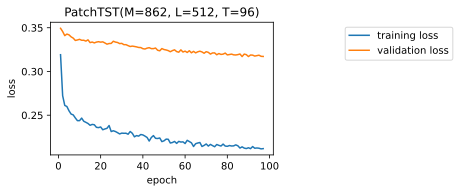

In [192]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# lr = 0.0001
runner3 = (
    ExperimentRunner(PatchTST)
        .with_epochs(100)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results3 = runner3.run(verbosity=1)

lookback window, future truth, future prediction torch.Size([512]) torch.Size([96]) (96,)


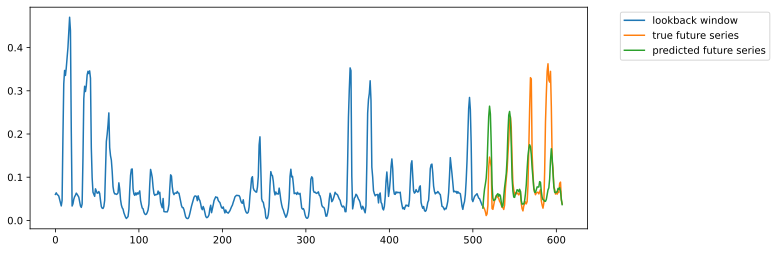

In [254]:
# Model trained on randomized channels.
show_random_prediction(runner3.get_results()[0].model, val_loader_all, scaler_all_data)

### Testing Learning Rate scheduling using `OneCycleLR`

Configurations in comments.

Running experiment: PatchTST(M=862, L=512, T=96)
epoch  1  train loss 0.449  val loss 0.375  (70s)
epoch  2  train loss 0.312  val loss 0.347  (71s)
epoch  3  train loss 0.284  val loss 0.339  (70s)
epoch  4  train loss 0.276  val loss 0.337  (71s)
epoch  5  train loss 0.268  val loss 0.337  (71s)
epoch  6  train loss 0.262  val loss 0.335  (71s)
epoch  7  train loss 0.260  val loss 0.337  (71s)
epoch  8  train loss 0.255  val loss 0.337  (71s)
epoch  9  train loss 0.257  val loss 0.338  (70s)
epoch 10  train loss 0.255  val loss 0.340  (70s)
epoch 11  train loss 0.255  val loss 0.340  (71s)
epoch 12  train loss 0.256  val loss 0.344  (70s)
epoch 13  train loss 0.250  val loss 0.341  (70s)
epoch 14  train loss 0.254  val loss 0.343  (71s)
epoch 15  train loss 0.247  val loss 0.344  (70s)
epoch 16  train loss 0.251  val loss 0.344  (71s)


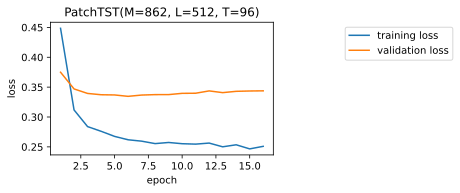

In [261]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# OneCycleLR scheduler, max_lr ~10x~ 3x higher than runner's lr. (10x was slowly gaining error.)
runner4 = (
    ExperimentRunner(PatchTST)
        .with_epochs(100)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results4 = runner4.run(verbosity=1)

lookback window, future truth, future prediction torch.Size([512]) torch.Size([96]) (96,)


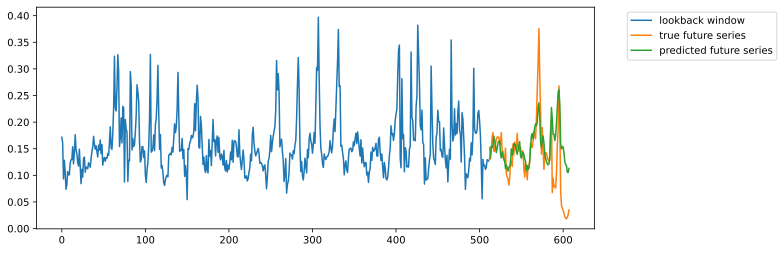

In [277]:
show_random_prediction(runner4.get_results()[0].model, val_loader_all, scaler_all_data)

Running experiment: PatchTST(M=862, L=512, T=96)
epoch  1  train loss 0.583  val loss 0.477  (69s)
epoch  2  train loss 0.397  val loss 0.401  (70s)
epoch  3  train loss 0.348  val loss 0.372  (70s)
epoch  4  train loss 0.320  val loss 0.357  (70s)
epoch  5  train loss 0.306  val loss 0.349  (70s)
epoch  6  train loss 0.292  val loss 0.344  (70s)
epoch  7  train loss 0.283  val loss 0.340  (70s)
epoch  8  train loss 0.278  val loss 0.338  (70s)
epoch  9  train loss 0.274  val loss 0.336  (70s)
epoch 10  train loss 0.269  val loss 0.335  (70s)
epoch 11  train loss 0.265  val loss 0.334  (70s)
epoch 12  train loss 0.265  val loss 0.334  (70s)
epoch 13  train loss 0.261  val loss 0.333  (70s)
epoch 14  train loss 0.259  val loss 0.332  (70s)
epoch 15  train loss 0.256  val loss 0.332  (70s)
epoch 16  train loss 0.257  val loss 0.331  (70s)
epoch 17  train loss 0.256  val loss 0.332  (70s)
epoch 18  train loss 0.254  val loss 0.332  (70s)
epoch 19  train loss 0.253  val loss 0.331  (70s)
e

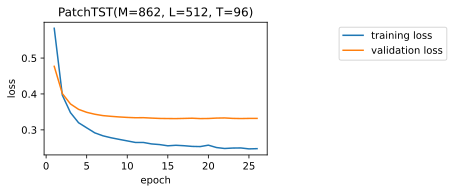

In [264]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# OneCycleLR scheduler, max_lr=0.0001 (runner's lr).
runner5 = (
    ExperimentRunner(PatchTST)
        .with_epochs(200)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results5 = runner5.run(verbosity=1)

lookback window, future truth, future prediction torch.Size([512]) torch.Size([96]) (96,)


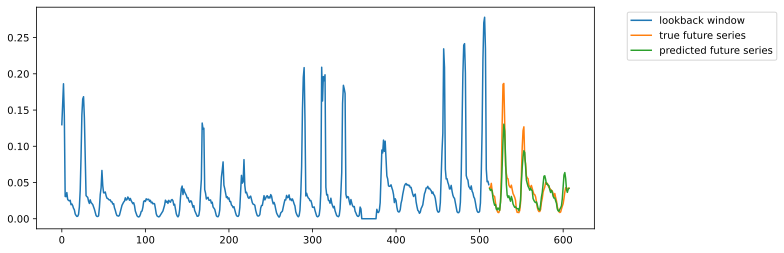

In [268]:
show_random_prediction(runner5.get_results()[0].model, val_loader_all, scaler_all_data)

Running experiment: PatchTST(M=862, L=512, T=96)
epoch  1  train loss 0.593  val loss 0.480  (69s)
epoch  2  train loss 0.400  val loss 0.401  (70s)
epoch  3  train loss 0.346  val loss 0.370  (70s)
epoch  4  train loss 0.318  val loss 0.355  (70s)
epoch  5  train loss 0.300  val loss 0.346  (70s)
epoch  6  train loss 0.286  val loss 0.341  (70s)
epoch  7  train loss 0.280  val loss 0.338  (70s)
epoch  8  train loss 0.274  val loss 0.335  (70s)
epoch  9  train loss 0.268  val loss 0.334  (70s)
epoch 10  train loss 0.265  val loss 0.333  (70s)
epoch 11  train loss 0.261  val loss 0.333  (70s)
epoch 12  train loss 0.261  val loss 0.332  (70s)
epoch 13  train loss 0.259  val loss 0.333  (70s)
epoch 14  train loss 0.257  val loss 0.334  (70s)
epoch 15  train loss 0.255  val loss 0.333  (70s)
epoch 16  train loss 0.256  val loss 0.333  (70s)
epoch 17  train loss 0.253  val loss 0.333  (70s)
epoch 18  train loss 0.251  val loss 0.333  (70s)
epoch 19  train loss 0.251  val loss 0.334  (70s)
e

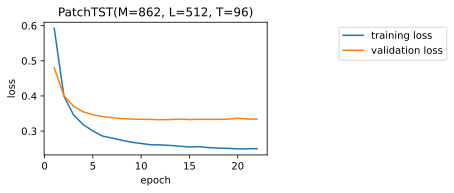

In [ ]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# OneCycleLR scheduler, pct_start=0.2 (new), max_lr=0.0001 (runner's lr).
runner6 = (
    ExperimentRunner(PatchTST)
        .with_epochs(200)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=96,
            )
        ).with_plots()
)

results6 = runner6.run(verbosity=1)

#### Summary: Learning Rate Scheduling

Example config,
```python
scheduler = torch.optim.lr_scheduler.OneCycleLR(
	optimizer,
	max_lr=self.lr,
	epochs=self.epochs,
	steps_per_epoch=len(self.train_loader))
```

The loss graphs look very stable, and convergence happens much faster than `runner3`, but loss does not reach a low enough value.

### Larger batch size, lookback $L = 512$, forecast $T = 192$

In [ ]:
all_data = load_time_series_data("./data/traffic.txt", delimiter=",")
train_loader_all, val_loader_all, test_loader_all, scaler_all_data = split_time_series_data(
    all_data,
    lookback_size=512,
    prediction_size=192,
    batch_size=64,
    use_randomized_loaders=False)

train_batch_X, train_batch_Y, sampled_channels_per_item = next(iter(train_loader_all))
print("All data shape:        ", all_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("random channels shape: ", sampled_channels_per_item.shape)
print("num batches:           ", len(train_loader_all))
print("total training samples:", len(train_loader_all.dataset))

val_batch_X, val_batch_Y = next(iter(val_loader_all))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(val_loader_all))
print("total val samples:     ", len(val_loader_all.dataset))

test_batch_X, test_batch_Y = next(iter(test_loader_all))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(test_loader_all))
print("total test samples:    ", len(test_loader_all.dataset))

All data shape:         (17544, 862)
training batch_X shape: torch.Size([64, 10, 512])
training batch_Y shape: torch.Size([64, 10, 192])
random channels shape:  torch.Size([64, 10])
num batches:            181
total training samples: 11577

val batch_X shape:      torch.Size([64, 862, 512])
val batch_Y shape:      torch.Size([64, 862, 192])
num batches:            25
total val samples:      1563

test batch_X shape:     torch.Size([64, 862, 512])
test batch_Y shape:     torch.Size([64, 862, 192])
num batches:            52
total test samples:     3319


Running experiment: PatchTST(M=862, L=512, T=192)
  train time 14s
  eval time 53s
epoch  1  train loss 0.363  val loss 0.351  (67s)
Allocated: 1.91 GB | Reserved: 10.47 GB | Peak: 8.70 GB
  train time 14s
  eval time 53s
epoch  2  train loss 0.280  val loss 0.346  (67s)
  train time 14s
  eval time 53s
epoch  3  train loss 0.272  val loss 0.344  (67s)
  train time 14s
  eval time 53s
epoch  4  train loss 0.266  val loss 0.342  (67s)
  train time 14s
  eval time 53s
epoch  5  train loss 0.261  val loss 0.342  (67s)
  train time 14s
  eval time 53s
epoch  6  train loss 0.261  val loss 0.341  (67s)
Allocated: 1.91 GB | Reserved: 10.47 GB | Peak: 8.71 GB
  train time 14s
  eval time 53s
epoch  7  train loss 0.261  val loss 0.342  (67s)
  train time 14s
  eval time 53s
epoch  8  train loss 0.256  val loss 0.343  (67s)
  train time 14s
  eval time 53s
epoch  9  train loss 0.255  val loss 0.340  (67s)
  train time 14s
  eval time 53s
epoch 10  train loss 0.255  val loss 0.340  (67s)
  train 

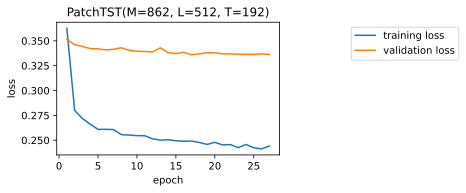

In [8]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# lr = 0.0001, no scheduler.
runner7 = (
    ExperimentRunner(PatchTST)
        .with_epochs(100)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=192,
            )
        ).with_plots()
)

results7 = runner7.run(verbosity=2)

In [11]:
results7

,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=862, L=512, T=192)",0.336,27,1980864


lookback window, future truth, future prediction torch.Size([512]) torch.Size([192]) (192,)


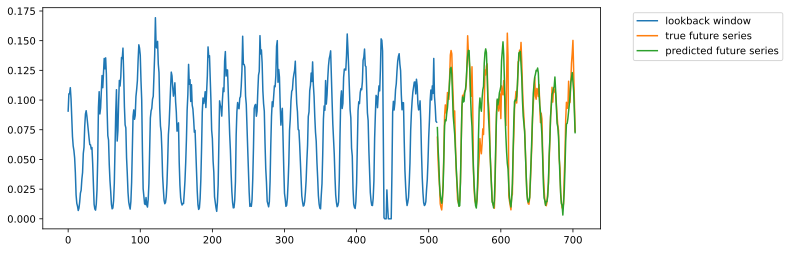

In [18]:
show_random_prediction(runner7.get_results()[0].model, val_loader_all, scaler_all_data)

### Lookback $L = 336$, forecast $T = 192$

In [22]:
all_data = load_time_series_data("./data/traffic.txt", delimiter=",")
train_loader_all, val_loader_all, test_loader_all, scaler_all_data = split_time_series_data(
    all_data,
    lookback_size=336,
    prediction_size=192,
    batch_size=64,
    use_randomized_loaders=False)

train_batch_X, train_batch_Y, sampled_channels_per_item = next(iter(train_loader_all))
print("All data shape:        ", all_data.shape)
print("training batch_X shape:", train_batch_X.shape)
print("training batch_Y shape:", train_batch_Y.shape)
print("random channels shape: ", sampled_channels_per_item.shape)
print("num batches:           ", len(train_loader_all))
print("total training samples:", len(train_loader_all.dataset))

val_batch_X, val_batch_Y = next(iter(val_loader_all))
print("\nval batch_X shape:     ", val_batch_X.shape)
print("val batch_Y shape:     ", val_batch_Y.shape)
print("num batches:           ", len(val_loader_all))
print("total val samples:     ", len(val_loader_all.dataset))

test_batch_X, test_batch_Y = next(iter(test_loader_all))
print("\ntest batch_X shape:    ", test_batch_X.shape)
print("test batch_Y shape:    ", test_batch_Y.shape)
print("num batches:           ", len(test_loader_all))
print("total test samples:    ", len(test_loader_all.dataset))

All data shape:         (17544, 862)
training batch_X shape: torch.Size([64, 10, 336])
training batch_Y shape: torch.Size([64, 10, 192])
random channels shape:  torch.Size([64, 10])
num batches:            184
total training samples: 11753

val batch_X shape:      torch.Size([64, 862, 336])
val batch_Y shape:      torch.Size([64, 862, 192])
num batches:            25
total val samples:      1563

test batch_X shape:     torch.Size([64, 862, 336])
test batch_Y shape:     torch.Size([64, 862, 192])
num batches:            52
total test samples:     3319


Running experiment: PatchTST(M=862, L=336, T=192)
epoch  1  train loss 0.378  val loss 0.358  (42s)
epoch  2  train loss 0.287  val loss 0.352  (43s)
epoch  3  train loss 0.276  val loss 0.348  (43s)
epoch  4  train loss 0.272  val loss 0.349  (43s)
epoch  5  train loss 0.268  val loss 0.345  (43s)
epoch  6  train loss 0.266  val loss 0.346  (44s)
epoch  7  train loss 0.263  val loss 0.345  (44s)
epoch  8  train loss 0.262  val loss 0.345  (43s)
epoch  9  train loss 0.261  val loss 0.343  (44s)
epoch 10  train loss 0.258  val loss 0.343  (43s)
epoch 11  train loss 0.257  val loss 0.343  (44s)
epoch 12  train loss 0.257  val loss 0.342  (44s)
epoch 13  train loss 0.257  val loss 0.343  (43s)
epoch 14  train loss 0.253  val loss 0.342  (43s)
epoch 15  train loss 0.253  val loss 0.341  (44s)
epoch 16  train loss 0.254  val loss 0.342  (44s)
epoch 17  train loss 0.253  val loss 0.341  (44s)
epoch 18  train loss 0.252  val loss 0.341  (44s)
epoch 19  train loss 0.250  val loss 0.340  (44s)


,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=862, L=336, T=192)",0.3377,41,1437376


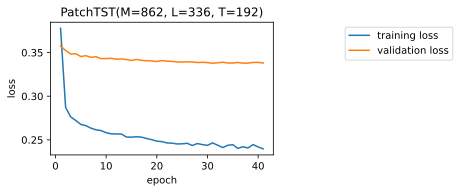

In [23]:
# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# lr = 0.0001, no scheduler.
runner8 = (
    ExperimentRunner(PatchTST)
        .with_epochs(100)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=336,
                prediction_size=192,
            )
        ).with_plots()
)

results8 = runner8.run(verbosity=1)
results8

lookback window, future truth, future prediction torch.Size([336]) torch.Size([192]) (192,)


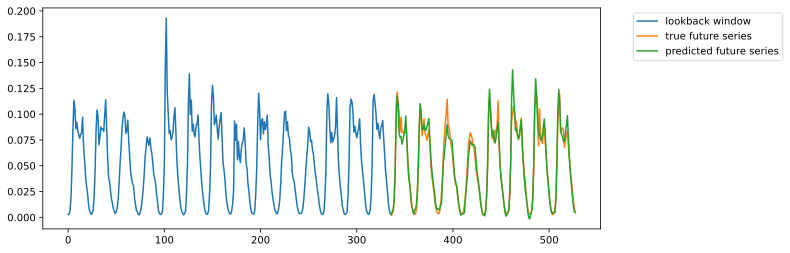

In [36]:
show_random_prediction(runner8.get_results()[0].model, val_loader_all, scaler_all_data)

## $L=512$, $P=720$

Running experiment: PatchTST(M=862, L=512, T=720)
epoch  1  train loss 0.361  val loss 0.409  (50s)
epoch  2  train loss 0.307  val loss 0.408  (50s)
epoch  3  train loss 0.300  val loss 0.407  (50s)
epoch  4  train loss 0.296  val loss 0.405  (50s)
epoch  5  train loss 0.293  val loss 0.405  (50s)
epoch  6  train loss 0.292  val loss 0.405  (50s)
epoch  7  train loss 0.288  val loss 0.403  (50s)
epoch  8  train loss 0.288  val loss 0.402  (50s)
epoch  9  train loss 0.285  val loss 0.402  (50s)
epoch 10  train loss 0.284  val loss 0.402  (50s)
epoch 11  train loss 0.283  val loss 0.402  (50s)
epoch 12  train loss 0.284  val loss 0.401  (51s)
epoch 13  train loss 0.280  val loss 0.400  (50s)
epoch 14  train loss 0.279  val loss 0.399  (50s)
epoch 15  train loss 0.279  val loss 0.400  (50s)
epoch 16  train loss 0.280  val loss 0.399  (50s)
epoch 17  train loss 0.277  val loss 0.399  (50s)
epoch 18  train loss 0.276  val loss 0.400  (50s)
epoch 19  train loss 0.275  val loss 0.398  (50s)


,Classifier,Loss (val),Epochs,Param count
0,"PatchTST(M=862, L=512, T=720)",0.3905,65,6306768


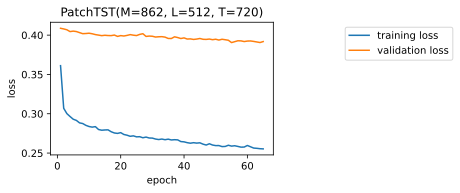

In [7]:
all_data = load_time_series_data("./data/traffic.txt", delimiter=",")
train_loader_all, val_loader_all, test_loader_all, scaler_all_data = split_time_series_data(
    all_data,
    lookback_size=512,
    prediction_size=720,
    batch_size=36,
    use_randomized_loaders=False)

# DEFAULT_CHANNEL_WINDOW_SIZE = 10.
# Evaluation done across the entire val set. Training done with randome channels.
# lr = 0.0001, no scheduler.
runner9 = (
    ExperimentRunner(PatchTST)
        .with_epochs(100)
        .with_data(train_loader_all, val_loader_all)
        .add_experiments(
            PatchTSTParams(
                num_channels=all_data.shape[1],  # This param doesn't really need to match if affine=False in RevIn
                lookback_size=512,
                prediction_size=720,
            )
        ).with_plots()
)

results9 = runner9.run(verbosity=1)
results9

lookback window, future truth, future prediction torch.Size([512]) torch.Size([720]) (720,)
lookback window, future truth, future prediction torch.Size([512]) torch.Size([720]) (720,)
lookback window, future truth, future prediction torch.Size([512]) torch.Size([720]) (720,)
lookback window, future truth, future prediction torch.Size([512]) torch.Size([720]) (720,)
lookback window, future truth, future prediction torch.Size([512]) torch.Size([720]) (720,)


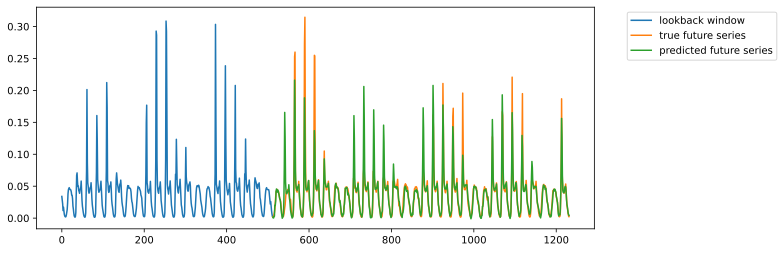

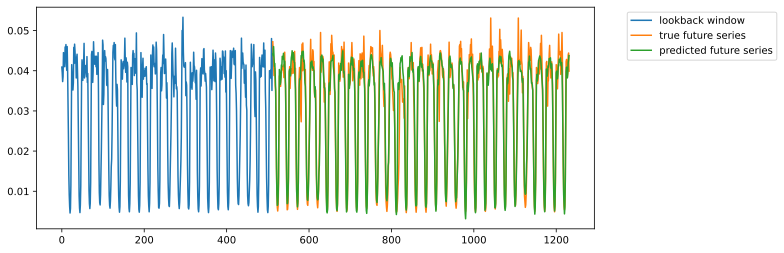

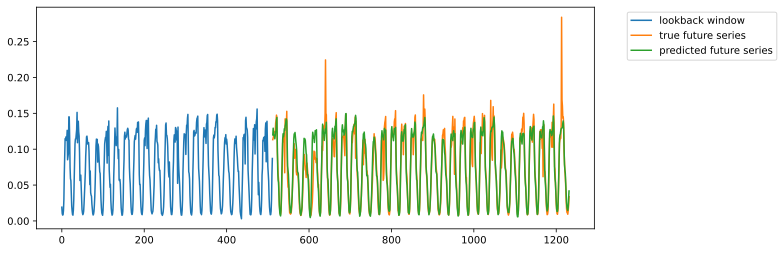

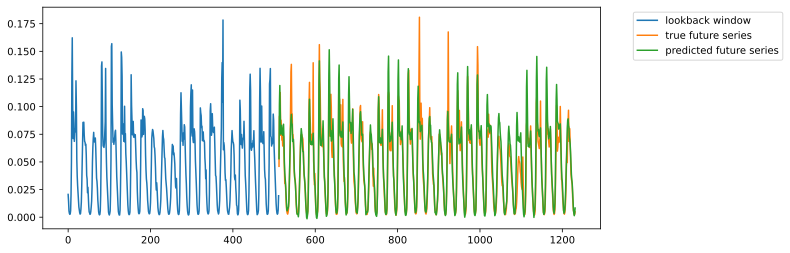

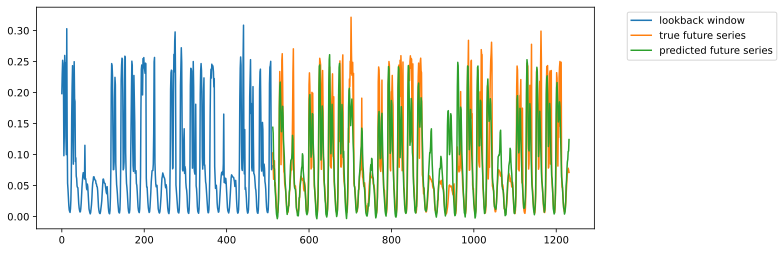

In [8]:
for _ in range(5):
    show_random_prediction(
        runner9.get_results()[0].model,
        val_loader_all,
        scaler_all_data)

In [10]:
evaluate(runner9.get_results()[0].model, test_loader_all, nn.MSELoss())

0.4392925293360613

Test set loss. Paper's published result for $L=512$, $P=720$ is 0.432.

## TODO:

- Change experiment runner to take in full dataset and make loaders as needed, then run many experiments in one runner.
- Memory issues led me to limiting the channel count and batch size. It would be interesting to see how the model performs on channels that are held back from the training data.
- Test resilience to distribution shift over time. Train on early data, test on much later (unseen) data. Generate dataset that gradually builds through time.
- Randomize where the val/test splits come out of the data. Right now they are the last time steps.
- Understand and highlight channel-independence in the model. That is a key architectural decision we need to explore. Include sketch in final notebook (see desk notes).